# Credit Card Transaction Analysis

Learn SQL and Python using **the external ULB/Worldline credit card dataset**. We will ask questions, summarize all 284,807 transactions in SQL, visualize small results in Python, and explain the limits.

**Before you start:** follow the README quick start to download the CSV and build the DuckDB database. Install `requirements-dev.txt` to run this notebook. Use **Run → Run All Cells** to reproduce it.

**Data source:** [ULB/Worldline on Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), via the [TensorFlow tutorial mirror](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data). Code and original explanations are MIT licensed; the dataset has separate ODbL/DbCL terms. See `docs/DATASET.md`.

We have amounts, elapsed time, anonymous PCA components, and fraud labels. We do not have merchants, customer IDs, or actual timestamps.

## 1. Connect to the local database

DuckDB handles the complete transaction table. `fetchdf()` turns each **small query result** into a pandas DataFrame for inspection. A context manager later closes the connection. First locate the project whether Jupyter starts in the project root or the notebook folder.

In [1]:
from pathlib import Path
import json
import sys
import duckdb
import pandas as pd
from IPython.display import display, Image, Markdown

here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / "sql/01_overview.sql").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the extracted project folder.")
database = ROOT / "data/processed/transactions.duckdb"
if not database.is_file():
    raise FileNotFoundError("Run python scripts/build_database.py from the project folder first.")
con = duckdb.connect(str(database), read_only=True)

def run_sql(filename):
    query = (ROOT / "sql" / filename).read_text(encoding="utf-8")
    print(query)
    return con.execute(query).fetchdf()

print("Connected to", database.name)

Connected to transactions.duckdb


## 2. Check data quality before interpreting results

The build validated all 31 fields. Empty values, non-finite values, negative amounts/times, and non-binary labels cause a failure. Zero amounts and exact duplicate rows are counted and retained. There is no source transaction ID to prove identical rows are duplicate events.

In [2]:
quality = json.loads(con.execute("SELECT report_json FROM data_quality").fetchone()[0])
display(pd.DataFrame([quality]).T.rename(columns={0: "value"}))

,value
row_count,284807
missing_or_nonfinite_rows,0
negative_rows,0
invalid_label_rows,0
zero_amount_rows,1825
exact_duplicate_extra_rows,1081
source_sha256,76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d...
duplicate_policy,Retained; source has no transaction identifiers.


## 3. How many transactions are labeled fraud?

`COUNT(*)` counts rows, `SUM(is_fraud)` counts fraud labels, and the average of a binary label is its rate. The percentage is the rate multiplied by 100. Compare the **mean** amount with the **median** to see the effect of large values.

In [3]:
overview = run_sql("01_overview.sql")
display(overview)
fraud_pct = overview.loc[0, "fraud_rate_pct"]
print(f"An always-non-fraud prediction would be {100 - fraud_pct:.4f}% accurate, but catch no fraud.")

-- COUNT counts transactions; SUM adds amounts; AVG computes the mean.
-- A binary label's average is its rate. Multiply by 100 for a percentage.
SELECT COUNT(*) AS transaction_count,
       SUM(is_fraud) AS fraud_count,
       ROUND(100.0 * AVG(is_fraud), 6) AS fraud_rate_pct,
       SUM(amount) AS total_amount,
       ROUND(AVG(amount), 2) AS mean_amount,
       MEDIAN(amount) AS median_amount,
       MAX(amount) AS maximum_amount,
       MIN(elapsed_seconds) AS first_elapsed_second,
       MAX(elapsed_seconds) AS last_elapsed_second
FROM transactions;



,transaction_count,fraud_count,fraud_rate_pct,total_amount,mean_amount,median_amount,maximum_amount,first_elapsed_second,last_elapsed_second
0,284807,492.0,0.172749,25162590.01,88.35,22.0,25691.16,0.0,172792.0


An always-non-fraud prediction would be 99.8273% accurate, but catch no fraud.


## 4. Compare labels with GROUP BY

SQL calculates one summary row for each label. Read the counts alongside average, median, and 95th percentile amounts. The labels are highly imbalanced; a count chart uses a logarithmic vertical axis so both bars are visible.

In [4]:
classes = run_sql("02_class_summary.sql")
display(classes)

-- GROUP BY gives one summary row per label. A median resists large outliers.
SELECT is_fraud,
       CASE WHEN is_fraud = 1 THEN 'Fraud' ELSE 'Non-fraud' END AS label,
       COUNT(*) AS transaction_count,
       SUM(amount) AS total_amount,
       ROUND(AVG(amount), 2) AS mean_amount,
       MEDIAN(amount) AS median_amount,
       QUANTILE_CONT(amount, 0.95) AS p95_amount
FROM transactions
GROUP BY is_fraud
ORDER BY is_fraud;



,is_fraud,label,transaction_count,total_amount,mean_amount,median_amount,p95_amount
0,0,Non-fraud,284315,25102462.04,88.29,22.00,364.4
1,1,Fraud,492,60127.97,122.21,9.25,640.9


## 5. Is transaction activity steady over the observation window?

Group by **elapsed hour since the first transaction**. This is not local time of day. Two days of observations cannot establish seasonality; the final hour may be partial.

In [5]:
hours = run_sql("03_elapsed_hours.sql")
display(hours.head(8))
print(f"Observed elapsed-hour groups: {len(hours)}")

-- These are hours since the first transaction, NOT local hours of the day.
SELECT elapsed_hour,
       COUNT(*) AS transaction_count,
       SUM(is_fraud) AS fraud_count,
       ROUND(100.0 * AVG(is_fraud), 6) AS fraud_rate_pct,
       SUM(amount) AS total_amount
FROM transactions
GROUP BY elapsed_hour
ORDER BY elapsed_hour;



,elapsed_hour,transaction_count,fraud_count,fraud_rate_pct,total_amount
0,0,3963,2.0,0.050467,257101.87
1,1,2217,2.0,0.090212,146105.69
2,2,1576,21.0,1.332487,108819.17
3,3,1821,13.0,0.713893,94306.84
4,4,1082,6.0,0.554529,79840.62
5,5,1681,11.0,0.654372,77125.92
6,6,1831,3.0,0.163845,142403.49
7,7,3368,23.0,0.682898,273305.98


Observed elapsed-hour groups: 48


## 6. Compare amount bands using CASE and a CTE

`CASE` assigns each row to a band. A **common table expression** (the `WITH` block) names an intermediate result. Band boundaries include the lower limit and exclude the upper. Compare both the fraud count and fraud rate; one without the other can hide the group size.

In [6]:
bands = run_sql("04_amount_bands.sql")
display(bands)
assert bands.transaction_count.sum() == overview.loc[0, "transaction_count"]
assert abs(bands.total_amount.sum() - overview.loc[0, "total_amount"]) < 0.01

-- CASE creates readable groups; a CTE gives the grouped input a name.
-- Intervals are [lower, upper), except the last which has no upper bound.
WITH banded AS (
    SELECT *, CASE WHEN amount < 10 THEN 1 WHEN amount < 50 THEN 2
                   WHEN amount < 100 THEN 3 WHEN amount < 500 THEN 4 ELSE 5 END AS band_order,
           CASE WHEN amount < 10 THEN '0 to <10' WHEN amount < 50 THEN '10 to <50'
                WHEN amount < 100 THEN '50 to <100' WHEN amount < 500 THEN '100 to <500'
                ELSE '500+' END AS amount_band
    FROM transactions
)
SELECT band_order, amount_band, COUNT(*) AS transaction_count,
       SUM(is_fraud) AS fraud_count,
       ROUND(100.0 * AVG(is_fraud), 6) AS fraud_rate_pct,
       SUM(amount) AS total_amount
FROM banded
GROUP BY band_order, amount_band
ORDER BY band_order;



,band_order,amount_band,transaction_count,fraud_count,fraud_rate_pct,total_amount
0,1,0 to <10,97314,249.0,0.255873,360375.95
1,2,10 to <50,92390,56.0,0.060613,2319062.28
2,3,50 to <100,37718,57.0,0.151121,2709959.87
3,4,100 to <500,47893,95.0,0.198359,9982528.36
4,5,500+,9492,35.0,0.368732,9790663.55


## 7. Use a window function to study concentration

`NTILE(10) OVER (...)` splits sorted transactions into ten nearly equal groups. Group 1 has the largest amounts. A windowed `SUM` gives the overall amount without collapsing each group's row. These are transaction groups, not groups of people.

In [7]:
concentration = run_sql("05_amount_concentration.sql")
display(concentration)
assert abs(concentration.share_of_total_amount_pct.sum() - 100) < 0.01

-- NTILE splits rows into ten almost equal-sized groups, largest amounts first.
-- transaction_id breaks ties; it is a local row key, not a source identifier.
WITH ranked AS (
    SELECT *, NTILE(10) OVER (ORDER BY amount DESC, transaction_id) AS amount_decile
    FROM transactions
), totals AS (
    SELECT amount_decile, COUNT(*) AS transaction_count,
           SUM(amount) AS total_amount, SUM(is_fraud) AS fraud_count
    FROM ranked GROUP BY amount_decile
)
SELECT *, ROUND(100.0 * total_amount / NULLIF(SUM(total_amount) OVER (), 0), 4)
           AS share_of_total_amount_pct
FROM totals
ORDER BY amount_decile;



,amount_decile,transaction_count,total_amount,fraud_count,share_of_total_amount_pct
0,1,28481,15651738.00,85.0,62.2024
1,2,28481,4079153.91,45.0,16.2112
2,3,28481,2227223.52,50.0,8.8513
3,4,28481,1339772.32,24.0,5.3245
4,5,28481,823729.13,17.0,3.2736
5,6,28481,491748.02,14.0,1.9543
6,7,28481,302583.79,13.0,1.2025
7,8,28480,166778.85,36.0,0.6628
8,9,28480,56588.65,77.0,0.2249
9,10,28480,23273.82,131.0,0.0925


## 8. Compare adjacent hours with LAG

`LAG` looks at the previous row in order. A recursive CTE fills missing hours so “previous” means the preceding elapsed hour. Percentage change is undefined when there is no previous observation or the previous count is zero.

In [8]:
changes = run_sql("06_hourly_change.sql")
display(changes.head(10))

-- A recursive CTE fills empty hours, then LAG compares with the preceding hour.
WITH RECURSIVE hours(elapsed_hour) AS (
    SELECT MIN(elapsed_hour) FROM transactions
    UNION ALL
    SELECT elapsed_hour + 1 FROM hours
    WHERE elapsed_hour < (SELECT MAX(elapsed_hour) FROM transactions)
), hourly AS (
    SELECT hours.elapsed_hour, COUNT(t.transaction_id) AS transaction_count
    FROM hours LEFT JOIN transactions t USING (elapsed_hour)
    GROUP BY hours.elapsed_hour
), changes AS (
    SELECT *, LAG(transaction_count) OVER (ORDER BY elapsed_hour) AS previous_count
    FROM hourly
)
SELECT *, ROUND(100.0 * (transaction_count - previous_count) / NULLIF(previous_count, 0), 2)
          AS change_pct
FROM changes ORDER BY elapsed_hour;



,elapsed_hour,transaction_count,previous_count,change_pct
0,0,3963,<NA>,NaN
1,1,2217,3963,-44.06
2,2,1576,2217,-28.91
3,3,1821,1576,15.55
4,4,1082,1821,-40.58
5,5,1681,1082,55.36
6,6,1831,1681,8.92
7,7,3368,1831,83.94
8,8,5179,3368,53.77
9,9,7878,5179,52.11


## 9. Why an amount threshold is not enough

Consider a simple alert: **amount ≥ threshold**. A true positive is a fraud-labeled alert. A false positive is a non-fraud-labeled alert.

- **Precision:** what fraction of alerts have a fraud label?
- **Recall:** what fraction of all fraud labels are captured?
- **Alert rate:** what fraction of all transactions create alerts?

We evaluate this rule on the same historical observations for explanation. There is no model training or held-out predictive evaluation. A zero denominator produces `NULL`, not zero.

In [9]:
rules = run_sql("07_threshold_tradeoffs.sql")
display(rules)
assert (rules.true_positives + rules.false_positives == rules.alert_count).all()
assert (rules.true_positives + rules.false_negatives == rules.total_fraud).all()

-- An educational rule: flag every amount >= a threshold. This is NOT a trained model.
-- Precision = labeled fraud among alerts; recall = labeled fraud captured / all labeled fraud.
-- NULLIF returns NULL when a metric has no denominator (for example, no alerts).
WITH thresholds(threshold_amount) AS (VALUES (100), (500), (1000)), counts AS (
    SELECT threshold_amount,
           COUNT(*) FILTER (WHERE amount >= threshold_amount) AS alert_count,
           COUNT(*) FILTER (WHERE amount >= threshold_amount AND is_fraud = 1) AS true_positives,
           SUM(is_fraud) AS total_fraud,
           COUNT(*) AS total_transactions
    FROM transactions CROSS JOIN thresholds
    GROUP BY threshold_amount
)
SELECT *, alert_count - true_positives AS false_positives,
       total_fraud - true_positives AS false_negatives,
       ROUND(100.0 * true_positives / NULLIF(alert_count, 0), 4) AS precision_pct,
       ROUND(100.0 * true_positives / NULLIF(total_fraud, 0), 4) AS recall_pct,
       ROUND(

,threshold_amount,alert_count,true_positives,total_fraud,total_transactions,false_positives,false_negatives,precision_pct,recall_pct,alert_rate_pct
0,100,57385,130,492.0,284807,57255,362.0,0.2265,26.4228,20.1487
1,500,9492,35,492.0,284807,9457,457.0,0.3687,7.1138,3.3328
2,1000,3069,9,492.0,284807,3060,483.0,0.2933,1.8293,1.0776


## 10. Generate the Python charts and reproducible report

The analysis script runs every numbered SQL file, writes small aggregate CSVs, and plots the results with Matplotlib. The raw table stays in DuckDB. The connection from the walkthrough is closed before reopening it in the analysis.

Saved 7 aggregate CSVs, 4 charts, quality checks, and findings to /workspace/work/credit-card-transaction-analysis/reports/generated


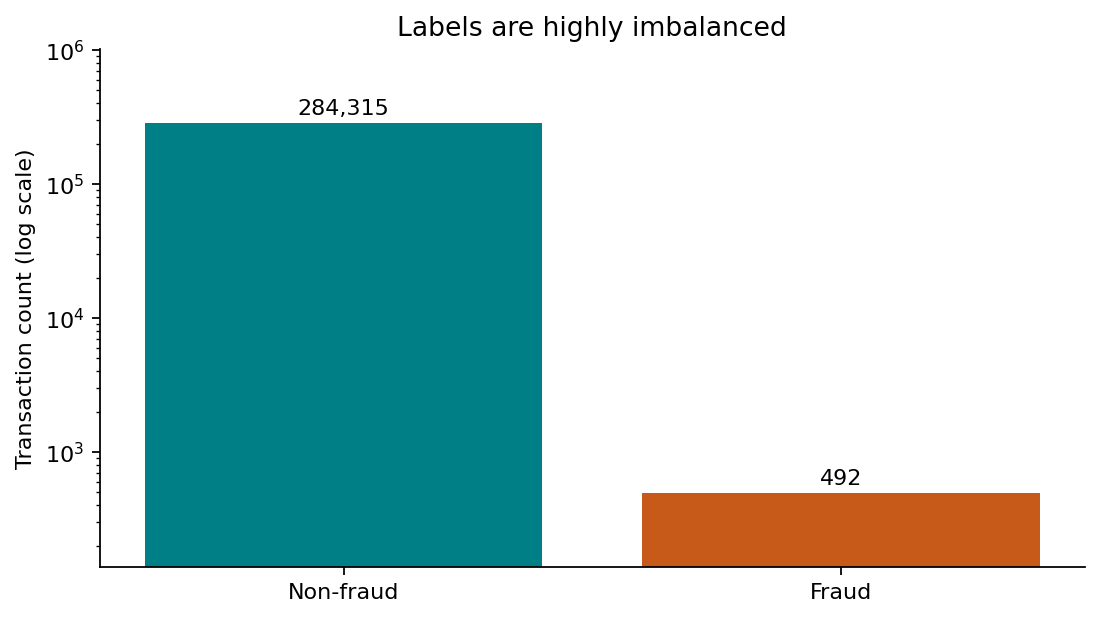

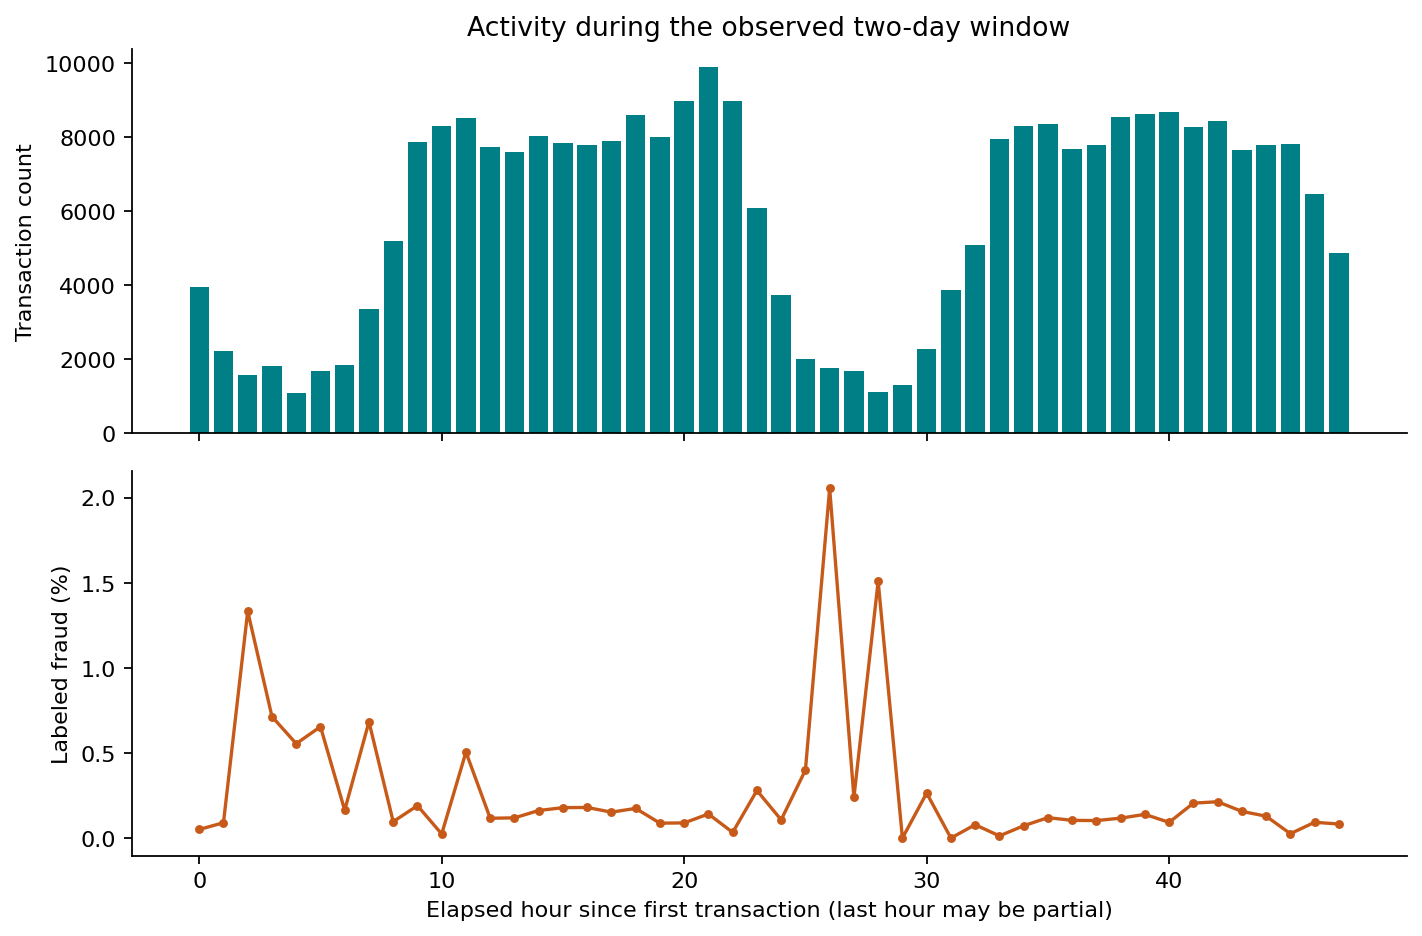

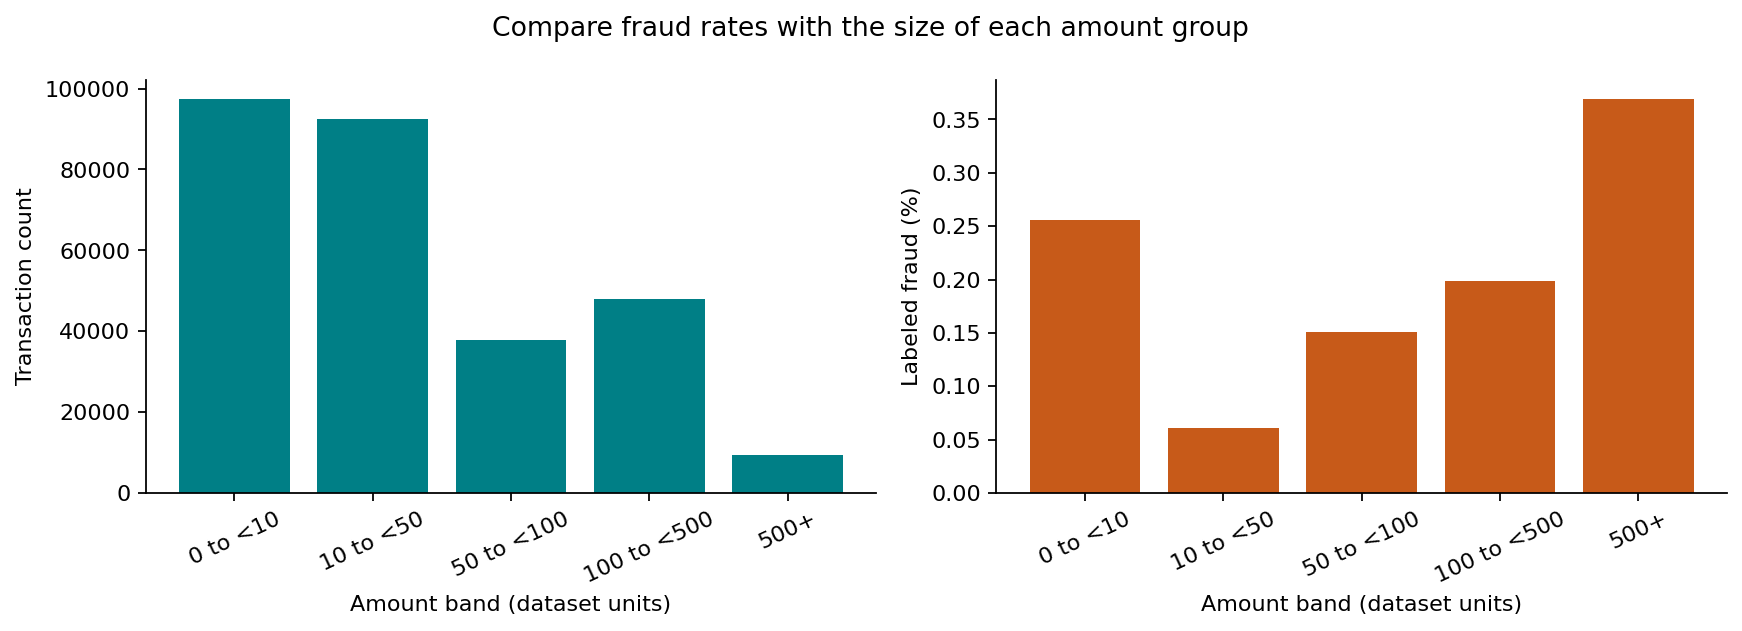

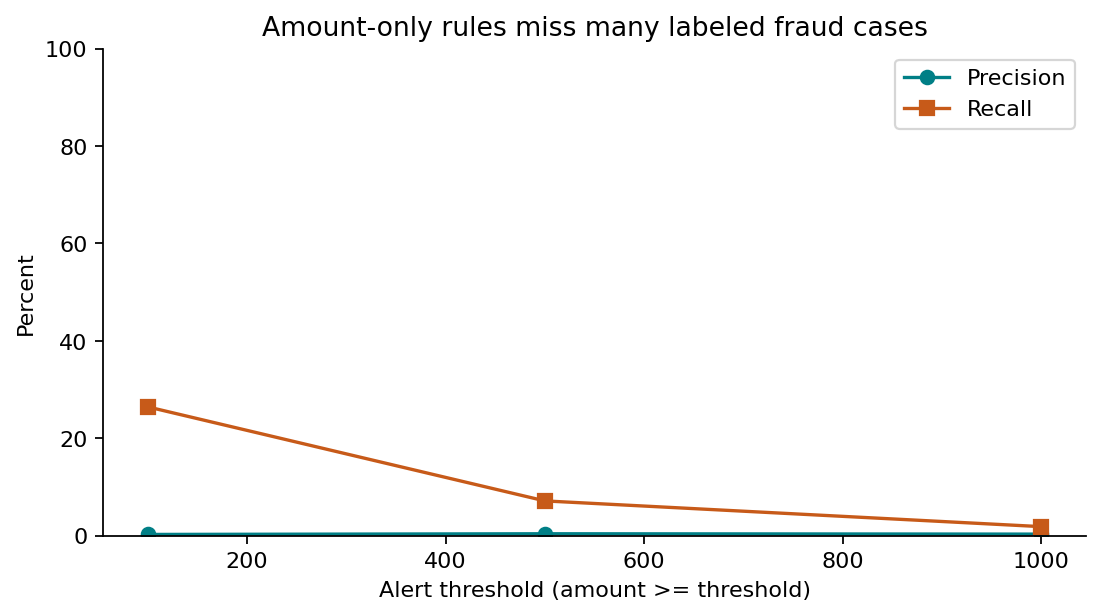

In [10]:
con.close()
sys.path.insert(0, str(ROOT / "scripts"))
from analyze import analyze

tables = analyze(database, ROOT / "reports/generated")
for filename in ["class_balance.png", "elapsed_hours.png", "amount_bands.png", "threshold_tradeoffs.png"]:
    display(Image(filename=str(ROOT / "reports/generated" / filename)))

## 11. Tell the story carefully

Open the generated findings and use the numbers to write your own explanation. Report the denominator with each rate. Transaction amounts on fraud-labeled rows are **not measured losses**. Anonymized components do not reveal customer traits, and relationships in this dataset do not establish causes.

In [11]:
findings = (ROOT / "reports/generated/findings.md").read_text(encoding="utf-8")
# Charts were displayed above; show the prose and numerical table here.
display(Markdown("\n".join(line for line in findings.splitlines() if not line.startswith("!["))))

# Credit Card Transaction Analysis — findings

Source: ULB/Worldline 2013 dataset, obtained from TensorFlow's public CSV mirror.
Input SHA-256: `76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89`.

- Transactions: **284,807**; labeled fraud: **492** (**0.1727%**).
- Mean amount: **88.35**; median: **22.00**; maximum: **25,691.16** (dataset amount units).
- Total amount: **25,162,590.01**. Amount on fraud-labeled rows: **60,127.97**. This is transaction value, not measured financial loss.
- The largest-amount decile accounts for **62.20%** of total amount. This is a transaction-level measure; customers cannot be identified.
- Exact duplicate extra rows: **1,081**; retained because the source has no unique transaction identifiers.
- Zero-amount rows: **1,825**; retained as valid source observations.
- Missing/non-finite rows: **0**; negative time/amount rows: **0**; invalid-label rows: **0**.

## Simple alert rules

These in-sample descriptions are educational and do not establish predictive performance.

| Threshold | Alerts | Labeled fraud caught | Precision % | Recall % |
| ---: | ---: | ---: | ---: | ---: |
| 100 | 57,385 | 130 | 0.2265 | 26.4228 |
| 500 | 9,492 | 35 | 0.3687 | 7.1138 |
| 1000 | 3,069 | 9 | 0.2933 | 1.8293 |





## Interpretation limits

The observation period is about two days in 2013. Elapsed hour is not local clock time. These results do not support monthly trends, seasonal patterns, merchant comparisons, customer segmentation, or conclusions about today's card transactions. V1–V28 are anonymized PCA components, not identifiable customer attributes. Labels describe the source observations; an association does not establish a cause.

Code and original documentation: MIT. External dataset: separate source terms; see ../../docs/DATASET.md. Raw data is not included in this repository.

## Your turn

1. Add threshold 250 to the alert query. Compare alert volume, precision, and recall.
2. Find elapsed hours with at least 1,000 observations, then rank their fraud rates.
3. Explain why exact duplicate rows were retained. What additional evidence would justify dropping them?
4. Write three observations and two limitations in your own words.

See `docs/EXERCISES.md` for solutions. For a future predictive project, use a chronological split and evaluate precision/recall on held-out data. This descriptive project makes no claim of real-time fraud detection.

**Attribution:** Worldline and ULB Machine Learning Group, dataset linked at the top. Dataset citation: Dal Pozzolo, Caelen, Johnson, and Bontempi, *Calibrating Probability with Undersampling for Unbalanced Classification*, IEEE CIDM, 2015. Dataset terms remain separate from the MIT-licensed code.